# Positional Hydra: pilot test of location-aware Hydra features

**Author:** Shreed. **Notebook:** `shreed_positional_hydra.ipynb` (pilot; extends `shreed_hydra_baseline.ipynb`).

## Idea

**What Hydra measures.** For every kernel, Hydra counts how often it wins the competition inside its group, **summed over the whole series**. It is a *bag of patterns*: it knows **which** patterns occur, but not **where** they occur.

**What its competitors do.**
- The dictionary methods Hydra is compared against (S-BOSS, TDE) gained accuracy by counting words separately in sub-windows of the series (a *spatial pyramid*).
- MultiRocket adds location through MIPV pooling (mean index of positive values).

**Hypothesis.** Adding coarse location to Hydra should help on series where *position matters*:
- aligned ECG beats
- image outlines
- spectra, where position = wavelength
- synthetic datasets built around order or location (TwoPatterns, SmoothSubspace, SyntheticControl, CBF)

On a location-free problem (ShapeletSim) it should **not** help.

**Two variants are tested:**
- **Variant A, spatial pyramid.** Count wins separately in `S` equal segments of the series, for each level `S` in `levels`, e.g. `(1, 2, 4)`.
- **Variant B, mean position.** Add, for each kernel, the mean (normalised) position of its max-wins.

This is a **pilot** (11 datasets × 5 splits). Its job is to decide whether the idea is worth scaling to 40 or 112 datasets.

**Correctness first.** Our team has already found five "improvements" that turned out to be bugs. The equivalence tests in Section 3 must all print `PASS` before any result is computed.

## What the official code does (read from `hydra-authors-repo/code/hydra.py`)

**Construction.**
- `Hydra(input_length, k=8, g=64, seed=None)`, with `divisor = min(2, g)` and `h = g // divisor`.
- `W` has shape `(num_dilations, divisor, k·h, 1, 9)`. It is drawn from N(0,1), mean-centred and divided by its L1 norm.
- `dilations = 2**arange(floor(log2((L-1)/8)) + 1)` and `paddings = (9-1)·d // 2`.

**`forward(X)`.** For each dilation `d` and each `diff_index` (0 = raw `X`, 1 = `torch.diff(X)`):
- **Convolution:** `conv1d(..., dilation=d, padding=p)` is reshaped to `Z` of shape `(n, h, k, T)`. Because padding = 4d keeps the length, **T = L for the raw series and T = L − 1 for the difference**.
- **Soft max count:** `count_max` = `scatter_add` of the max **values** at the argmax over `k`.
- **Hard min count:** `count_min` = `scatter_add` of **ones** at the argmin over `k`.
- **Order:** it appends `count_max` and then `count_min`, each `(n, h, k)`, concatenates along dim 1 and flattens.

So inside each `(d, diff_index)` block the layout is `[soft: h groups × k][hard: h groups × k]`.

**Positional Hydra layout.**
- **Blocks:** same `(d, diff_index)` order as the official code.
- **Inside each block:** `[S=1 soft, S=1 hard, S=2 soft, S=2 hard, S=4 soft, S=4 hard, (mean position)]`.
- **Inside one level:** each tensor is `(n, h, k·S)` and is flattened group-major, with bin `kernel·S + segment` (kernel-major).
- **Equivalence:** with `levels=(1,)` and no mean position, the output is exactly the official output (Test 1).

## 1. Setup

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

REPO_DIR = PROJECT_DIR / "hydra-authors-repo"
DATA_DIR = PROJECT_DIR / "data" / "ucr_tsml"
RESULTS_DIR = PROJECT_DIR / "results" / "Shreed"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

PILOT_CSV = RESULTS_DIR / "positional_hydra_pilot.csv"              # new file
MR_CSV = RESULTS_DIR / "positional_hydra_pilot_multirocket.csv"     # new file (only if RUN_MULTIROCKET)
BASELINE_CSV = RESULTS_DIR / "hydra_default_baseline.csv"           # read only

print("Project directory:", PROJECT_DIR.resolve())
print("Dataset directory:", DATA_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())

Project directory: /Users/shreed/PROJECTS/Hydra_1
Dataset directory: /Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml
Results directory: /Users/shreed/PROJECTS/Hydra_1/results/Shreed


In [2]:
import importlib.util
import random
import sys
import traceback
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from aeon.datasets import load_classification
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

# Ridge with a small alpha on n_train << n_features can hit a near-singular Gram matrix; sklearn then
# warns and falls back to least squares. These are warnings, not errors.
from scipy.linalg import LinAlgWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="Singular matrix in solving dual problem")

print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__)

numpy 2.3.5 | pandas 3.0.6 | torch 2.15.0


In [15]:
# ---- Experiment configuration (one place to change for the scale-up) ----
PILOT_DATASETS = {
    # name: (group, type)
    "SmoothSubspace":              ("location_by_design", "Simulated"),
    "SyntheticControl":            ("location_by_design", "Simulated"),
    "TwoPatterns":                 ("location_by_design", "Simulated"),
    "CBF":                         ("location_by_design", "Simulated"),
    "ShapeletSim":                 ("control",            "Simulated"),
    "ECG200":                      ("aligned_real",       "ECG"),
    "DistalPhalanxOutlineCorrect": ("aligned_real",       "Image"),
    "Lightning7":                  ("aligned_real",       "Sensor"),
    "EthanolLevel":                ("aligned_real",       "Spectro"),
    "Ham":                         ("aligned_real",       "Spectro"),
    "Wine":                        ("aligned_real",       "Spectro"),
}
RESAMPLES = [0, 1, 2, 3, 4]          # 0 = default UCR split; 1-4 = stratified resamples. Also the Hydra seed.

K = 8
ALPHAS = np.logspace(-3, 3, 10)      # team-wide ridge alpha grid
BATCH_SIZE = 256
TEST_CHUNK = 1024                    # test set is transformed / scaled / predicted in chunks (bounded memory)

VARIANTS = {
    # name: dict(levels, mean_position, g, official)
    "hydra":               dict(levels=(1,),      mean_position=False, g=64, official=True),
    "pyr124_same_kernels": dict(levels=(1, 2, 4), mean_position=False, g=64, official=False),
    "pyr124_equal_budget": dict(levels=(1, 2, 4), mean_position=False, g=10, official=False),
    "pyr12_equal_budget":  dict(levels=(1, 2),    mean_position=False, g=22, official=False),
    "meanpos":             dict(levels=(1,),      mean_position=True,  g=64, official=False),
}

RUN_MULTIROCKET = True              # optional check: does the gain survive MultiRocket's own location feature?


def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [4]:
# ---- Import the authors' Hydra BY FILE PATH (pip `hydra-core` would shadow `import hydra`) ----
HYDRA_SOURCE = REPO_DIR / "code" / "hydra.py"
assert HYDRA_SOURCE.exists(), f"Missing official implementation: {HYDRA_SOURCE}"

spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)

Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler

_probe = Hydra(96, k=K, g=64, seed=0)
for attr in ["k", "g", "h", "divisor", "dilations", "num_dilations", "paddings", "W"]:
    assert hasattr(_probe, attr), f"Official Hydra has no attribute '{attr}'"
assert _probe.W.shape == (_probe.num_dilations, _probe.divisor, _probe.k * _probe.h, 1, 9)
print("Hydra loaded from:", HYDRA_SOURCE.resolve())
print("Example (L=96): dilations", _probe.dilations.tolist(), "| paddings", _probe.paddings.tolist(),
      "| divisor", _probe.divisor, "| h", _probe.h, "| W", tuple(_probe.W.shape))
del _probe

Hydra loaded from: /Users/shreed/PROJECTS/Hydra_1/hydra-authors-repo/code/hydra.py
Example (L=96): dilations [1, 2, 4, 8] | paddings [4, 8, 16, 32] | divisor 2 | h 32 | W (4, 2, 256, 1, 9)


In [5]:
# ---- Data loading (same checks as Notebook 1) and stratified resampling ----
def load_ucr_dataset(dataset_name, extract_path=DATA_DIR):
    X_train, y_train = load_classification(
        name=dataset_name, split="train", extract_path=str(extract_path), return_metadata=False
    )
    X_test, y_test = load_classification(
        name=dataset_name, split="test", extract_path=str(extract_path), return_metadata=False
    )
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)

    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError(f"{dataset_name}: expected 3D arrays")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(f"{dataset_name}: expected univariate data")
    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(f"{dataset_name}: train/test lengths differ")
    if not set(np.unique(y_test)).issubset(set(np.unique(y_train))):
        raise ValueError(f"{dataset_name}: test labels include unseen classes")
    return X_train, y_train, X_test, y_test


def make_split(X_train, y_train, X_test, y_test, resample_id):
    # resample 0 = default UCR split. Otherwise pool train+test and draw a new train set with the
    # SAME per-class counts as the original train set (seeded by resample_id); the rest is the test set.
    if resample_id == 0:
        return X_train, y_train, X_test, y_test
    X = np.concatenate([X_train, X_test])
    y = np.concatenate([y_train, y_test])
    rng = np.random.RandomState(resample_id)
    classes, counts = np.unique(y_train, return_counts=True)
    train_idx = []
    for c, n_c in zip(classes, counts):
        idx_c = np.flatnonzero(y == c)
        train_idx.append(rng.choice(idx_c, size=n_c, replace=False))
    train_idx = np.sort(np.concatenate(train_idx))
    test_idx = np.setdiff1d(np.arange(len(y)), train_idx)

    assert len(np.intersect1d(train_idx, test_idx)) == 0, "train/test overlap"
    assert len(train_idx) == len(y_train) and len(test_idx) == len(y_test), "split sizes differ from default"
    assert dict(zip(*np.unique(y[train_idx], return_counts=True))) == dict(zip(classes, counts))
    return X[train_idx], y[train_idx], X[test_idx], y[test_idx]


def to_tensor(X):
    return torch.as_tensor(np.ascontiguousarray(X), dtype=torch.float32)

## 2. Implementation: `PositionalHydra`

- **Kernels.** It is built **from an official `Hydra` instance** created with the same `input_length, k, g, seed`, and copies `W`, `dilations` and `paddings`. For the same seed and `g`, the kernels are therefore *identical* to plain Hydra.
- **Forward pass.** `forward()` repeats the official conv and diff code line by line. Then, for each `(d, diff_index)` block with `Z` of shape `(n, h, k, T)` (T read from `Z`), it builds the features below.

**Spatial pyramid (Variant A).** For each level `S`:
- Every time step `t` gets a segment id `seg(t) = floor(t·S / T)`, from 0 to S−1. So S equal, contiguous segments.
- The soft count adds the max value into bin `argmax_kernel·S + seg(t)`.
- The hard count adds 1 into bin `argmin_kernel·S + seg(t)`.
- With `S = 1` this is exactly the official `count_max` / `count_min`.

**Mean position (Variant B).**
- Each time step gets a position `pos(t) = (t+1)/T`, in (0, 1].
- For each kernel: the sum of `pos` over its max-wins, divided by its number of max-wins.
- If a kernel never wins, the feature is exactly 0, so 0 is reserved for "no wins".

In [6]:
class PositionalHydra(nn.Module):
    # Hydra with location-aware counts. Kernels are copied from an official Hydra(input_length, k, g, seed).

    def __init__(self, input_length, k=8, g=64, seed=None, levels=(1,), mean_position=False):
        super().__init__()
        base = Hydra(input_length, k=k, g=g, seed=seed)       # official constructor -> identical kernels
        self.k, self.g, self.h, self.divisor = base.k, base.g, base.h, base.divisor
        self.dilations = base.dilations.clone()
        self.num_dilations = base.num_dilations
        self.paddings = base.paddings.clone()
        self.W = base.W.clone()
        self.levels = tuple(int(s) for s in levels)
        assert len(self.levels) > 0 and all(s >= 1 for s in self.levels)
        self.mean_position = bool(mean_position)
        self.input_length = input_length

        # every segment must be non-empty for raw (T = L) and diff (T = L - 1) blocks
        min_T = input_length - 1 if self.divisor > 1 else input_length
        assert min_T >= max(self.levels), f"T={min_T} is shorter than max level {max(self.levels)}"

        per_block = 2 * self.k * self.h * sum(self.levels) + (self.k * self.h if self.mean_position else 0)
        self.n_features = self.num_dilations * self.divisor * per_block

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        Z = []
        for batch in torch.arange(num_examples).split(batch_size):
            Z.append(self(X[batch]))
        return torch.cat(Z)

    def forward(self, X):
        num_examples = X.shape[0]
        if self.divisor > 1:
            diff_X = torch.diff(X)

        out = []
        for dilation_index in range(self.num_dilations):
            d = self.dilations[dilation_index].item()
            p = self.paddings[dilation_index].item()

            for diff_index in range(self.divisor):
                _Z = F.conv1d(X if diff_index == 0 else diff_X, self.W[dilation_index, diff_index],
                              dilation=d, padding=p).view(num_examples, self.h, self.k, -1)
                T = _Z.shape[-1]
                assert T >= max(self.levels), f"block T={T} < max level"

                max_values, max_indices = _Z.max(2)            # (n, h, T) float32 / int64
                # exactly the official calls (not argmin): tie-breaking on constant stretches, where every
                # mean-centred kernel outputs 0, must match the official code
                min_values, min_indices = _Z.min(2)            # (n, h, T)
                ones = torch.ones_like(max_values)

                for S in self.levels:
                    seg = (torch.arange(T) * S // T).expand_as(max_indices)      # int64 segment id 0..S-1
                    soft = torch.zeros(num_examples, self.h, self.k * S)
                    hard = torch.zeros(num_examples, self.h, self.k * S)
                    soft.scatter_add_(-1, max_indices * S + seg, max_values)
                    hard.scatter_add_(-1, min_indices * S + seg, ones)
                    out.append(soft.reshape(num_examples, -1))
                    out.append(hard.reshape(num_examples, -1))

                if self.mean_position:
                    pos = ((torch.arange(T, dtype=torch.float32) + 1) / T).expand_as(max_values)
                    pos_sum = torch.zeros(num_examples, self.h, self.k).scatter_add_(-1, max_indices, pos)
                    wins = torch.zeros(num_examples, self.h, self.k).scatter_add_(-1, max_indices, ones)
                    out.append((pos_sum / wins.clamp(min=1)).reshape(num_examples, -1))

        return torch.cat(out, 1)


def official_n_features(hydra):
    return hydra.num_dilations * hydra.divisor * 2 * hydra.k * hydra.h


def transform(model, X_tensor, batch_size=BATCH_SIZE):
    with torch.inference_mode():
        return model.batch(X_tensor, batch_size=batch_size)


def assert_same(a, b, name):
    # Exact equality preferred, allclose(atol=1e-6) accepted. Returns which one held.
    assert a.shape == b.shape, f"{name}: shape {tuple(a.shape)} != {tuple(b.shape)}"
    if torch.equal(a, b):
        return "equal"
    max_abs = (a - b).abs().max().item()
    assert torch.allclose(a, b, atol=1e-6, rtol=0), f"{name}: NOT equivalent, max |diff| = {max_abs:.3e}"
    return f"allclose (max |diff| {max_abs:.1e})"


def block_slices(model):
    # Column slices of every block and of every (level, soft/hard) part inside it, in output order.
    # Returns a list of dicts: {dilation_index, diff_index, parts: {(S, 'soft'|'hard'|'meanpos'): slice}}
    k, h = model.k, model.h
    blocks, col = [], 0
    for d in range(model.num_dilations):
        for v in range(model.divisor):
            parts = {}
            for S in model.levels:
                for kind in ("soft", "hard"):
                    parts[(S, kind)] = slice(col, col + h * k * S)
                    col += h * k * S
            if model.mean_position:
                parts[(1, "meanpos")] = slice(col, col + h * k)
                col += h * k
            blocks.append({"dilation_index": d, "diff_index": v, "parts": parts})
    assert col == model.n_features
    return blocks

## 3. Equivalence and sanity tests (must all PASS before any result is reported)

| Test | What it checks |
|---|---|
| 1 | `PositionalHydra(levels=(1,))` gives exactly the official `Hydra` output for the same seed (ECG200 L=96, Beef L=470; train and test) |
| 2 | Pyramid consistency: for `levels=(1,2,4)`, summing the level-S bins over segments recovers level 1, for every level and every block. Exact for hard counts, `allclose` for soft counts |
| 3 | Segment ids by hand on a tiny input (n=2, L=20): S=2 puts t=0..T/2−1 in segment 0. Every segment is non-empty for raw (T=20) and diff (T=19) blocks |
| 4 | Mean position: on a hand-built input where one kernel can only win in the first half, its mean position is ≤ 0.5. All positions lie in (0, 1], and kernels that never win are exactly 0 |
| 5 | Feature counts: `2·k·h·(1+2+4)` per block for the pyramid, `+k·h` per block for mean position, for every variant |
| 6 | The official Hydra on ECG200 (seed 0, default split) reproduces Notebook 1's 0.87 |

In [7]:
TEST_DATA = {}
for name in ["ECG200", "Beef"]:
    Xtr, ytr, Xte, yte = load_ucr_dataset(name)
    TEST_DATA[name] = (to_tensor(Xtr), ytr, to_tensor(Xte), yte)
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}")

# ---- Test 1: levels=(1,), no mean position == official Hydra ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    L = Xtr_t.shape[-1]
    for seed in [0, 1]:
        official = Hydra(L, k=K, g=64, seed=seed)
        pos1 = PositionalHydra(L, k=K, g=64, seed=seed, levels=(1,), mean_position=False)
        assert torch.equal(pos1.W, official.W), "kernels differ"
        r_tr = assert_same(transform(pos1, Xtr_t), transform(official, Xtr_t), f"Test 1 {name} s{seed} train")
        r_te = assert_same(transform(pos1, Xte_t), transform(official, Xte_t), f"Test 1 {name} s{seed} test")
        assert pos1.n_features == official_n_features(official) == transform(official, Xtr_t).shape[1]
        print(f"  {name} seed {seed}: train {r_tr}, test {r_te}")
print("Test 1 PASS: PositionalHydra(levels=(1,)) reproduces the official Hydra output")

ECG200: train (100, 1, 96), test (100, 1, 96)
Beef: train (30, 1, 470), test (30, 1, 470)
  ECG200 seed 0: train equal, test equal
  ECG200 seed 1: train equal, test equal
  Beef seed 0: train equal, test equal
  Beef seed 1: train equal, test equal
Test 1 PASS: PositionalHydra(levels=(1,)) reproduces the official Hydra output


In [8]:
# ---- Test 2: pyramid consistency (sum over segments == level 1), every level and every block ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    L = Xtr_t.shape[-1]
    pyr = PositionalHydra(L, k=K, g=64, seed=0, levels=(1, 2, 4))
    Z = transform(pyr, Xtr_t[:50])
    worst_soft = 0.0
    for blk in block_slices(pyr):
        for kind in ("soft", "hard"):
            lvl1 = Z[:, blk["parts"][(1, kind)]].reshape(len(Z), pyr.h, pyr.k)
            for S in (2, 4):
                lvlS = Z[:, blk["parts"][(S, kind)]].reshape(len(Z), pyr.h, pyr.k, S).sum(-1)
                if kind == "hard":
                    assert torch.equal(lvlS, lvl1), f"Test 2 hard {name} block {blk['dilation_index'], blk['diff_index']} S={S}"
                else:
                    assert torch.allclose(lvlS, lvl1, atol=1e-4, rtol=1e-5), f"Test 2 soft {name} S={S}"
                    worst_soft = max(worst_soft, (lvlS - lvl1).abs().max().item())
    # level-1 part of the pyramid must also equal the official features
    official = transform(Hydra(L, k=K, g=64, seed=0), Xtr_t[:50])
    lvl1_cols = torch.cat([torch.arange(blk["parts"][(1, kind)].start, blk["parts"][(1, kind)].stop)
                           for blk in block_slices(pyr) for kind in ("soft", "hard")])
    assert torch.equal(Z[:, lvl1_cols], official), "level-1 part of pyramid != official"
    print(f"  {name}: {len(block_slices(pyr))} blocks, hard exact, soft max |diff| {worst_soft:.1e}, "
          f"level-1 part == official")
print("Test 2 PASS: segment bins sum back to the level-1 (official) features")

  ECG200: 8 blocks, hard exact, soft max |diff| 7.6e-06, level-1 part == official
  Beef: 12 blocks, hard exact, soft max |diff| 5.3e-05, level-1 part == official
Test 2 PASS: segment bins sum back to the level-1 (official) features


In [9]:
# ---- Test 3: segment ids by hand, and non-empty segments for raw and diff blocks ----
for T in [20, 19]:                                    # raw block (T = L = 20) and diff block (T = L - 1 = 19)
    seg2 = torch.arange(T) * 2 // T
    seg4 = torch.arange(T) * 4 // T
    half = (T + 1) // 2                               # T=20 -> 10 (0..9 in seg 0);  T=19 -> 10 (0..9 in seg 0)
    assert seg2[:half].eq(0).all() and seg2[half:].eq(1).all(), f"S=2 segmentation wrong for T={T}"
    if T == 20:
        assert seg2.tolist() == [0] * 10 + [1] * 10
        assert seg4.tolist() == [0] * 5 + [1] * 5 + [2] * 5 + [3] * 5
    for S, seg in [(2, seg2), (4, seg4)]:
        counts = torch.bincount(seg, minlength=S)
        assert (counts > 0).all() and len(counts) == S and counts.max() - counts.min() <= 1, (T, S, counts)
        assert torch.all(seg[1:] >= seg[:-1]), "segments must be contiguous"
    print(f"  T={T}: S=2 sizes {torch.bincount(seg2).tolist()}, S=4 sizes {torch.bincount(seg4).tolist()}")

# The model itself on n=2, L=20: every segment of every kernel-group gets exactly its share of time steps
tiny = torch.randn(2, 1, 20, generator=torch.Generator().manual_seed(0))
m = PositionalHydra(20, k=K, g=64, seed=0, levels=(1, 2, 4))
Zt = transform(m, tiny)
for blk in block_slices(m):
    T = 20 if blk["diff_index"] == 0 else 19
    for S in (2, 4):
        hard = Zt[:, blk["parts"][(S, "hard")]].reshape(2, m.h, m.k, S)
        per_segment = hard.sum(2)                     # wins summed over kernels = time steps in that segment
        expected = torch.bincount(torch.arange(T) * S // T, minlength=S).float()
        assert torch.equal(per_segment, expected.expand_as(per_segment)), (blk, S)
print("Test 3 PASS: segment ids correct by hand; every segment non-empty for raw (T=L) and diff (T=L-1)")

  T=20: S=2 sizes [10, 10], S=4 sizes [5, 5, 5, 5]
  T=19: S=2 sizes [10, 9], S=4 sizes [5, 5, 5, 4]
Test 3 PASS: segment ids correct by hand; every segment non-empty for raw (T=L) and diff (T=L-1)


In [10]:
# ---- Test 4: mean position on a hand-built input ----
# Build a PositionalHydra on L=40 and overwrite ONE group's kernels (dilation 0, raw block, group 0):
# kernel 0 = centre tap only, so its output is x[t]; kernels 1..7 = all-zero kernels, output 0.
# Input: +1 in the first half, -1 in the second half. Kernel 0 (output +1) beats the zero kernels
# in the first half; in the second half it outputs -1 and loses to a zero kernel. So kernel 0 wins
# the argmax exactly at t = 0..19, and its mean position must be mean((t+1)/40) = 0.2625 <= 0.5.
L = 40
mp = PositionalHydra(L, k=K, g=64, seed=0, levels=(1,), mean_position=True)
W = mp.W.clone()
W[0, 0, :K] = 0.0
W[0, 0, 0, 0, 4] = 1.0                                 # centre tap -> conv output = x[t]
mp.W = W
x = torch.cat([torch.full((L // 2,), 1.0), torch.full((L // 2,), -1.0)]).view(1, 1, L)
Zm = transform(mp, x)
blk0 = block_slices(mp)[0]                             # dilation 0, raw block
assert (blk0["dilation_index"], blk0["diff_index"]) == (0, 0)
mpos = Zm[0, blk0["parts"][(1, "meanpos")]].reshape(mp.h, mp.k)

assert 0 < mpos[0, 0] <= 0.5, f"kernel 0 mean position {mpos[0, 0]:.3f} should be <= 0.5"
expected_k0 = ((torch.arange(L // 2) + 1) / L).mean().item()
assert abs(mpos[0, 0].item() - expected_k0) < 1e-6, (mpos[0, 0].item(), expected_k0)

# Whole output: positions lie in (0, 1] or are exactly 0 (never wins); zero <=> zero soft wins count
all_mp = torch.cat([Zm[:, b["parts"][(1, "meanpos")]] for b in block_slices(mp)], 1)
assert ((all_mp == 0) | ((all_mp > 0) & (all_mp <= 1))).all(), "positions outside (0, 1]"
# a kernel that never wins: compare with the official hard/soft win structure via a direct recount
Xb = TEST_DATA["ECG200"][0][:20]
mp2 = PositionalHydra(Xb.shape[-1], k=K, g=64, seed=0, levels=(1,), mean_position=True)
Z2 = transform(mp2, Xb)
n_zero, n_checked = 0, 0
with torch.inference_mode():
    diff_X = torch.diff(Xb)
    for b in block_slices(mp2):
        di, v = b["dilation_index"], b["diff_index"]
        _Z = F.conv1d(Xb if v == 0 else diff_X, mp2.W[di, v], dilation=mp2.dilations[di].item(),
                      padding=mp2.paddings[di].item()).view(len(Xb), mp2.h, mp2.k, -1)
        T = _Z.shape[-1]
        idx = _Z.max(2)[1]                                                  # (n, h, T), as in forward
        wins = F.one_hot(idx, mp2.k).sum(2).float()                         # (n, h, k)
        possum = (F.one_hot(idx, mp2.k).float() * ((torch.arange(T) + 1) / T).view(1, 1, T, 1)).sum(2)
        ref = torch.where(wins > 0, possum / wins.clamp(min=1), torch.zeros_like(wins))
        got = Z2[:, b["parts"][(1, "meanpos")]].reshape(len(Xb), mp2.h, mp2.k)
        assert torch.allclose(got, ref, atol=1e-6), f"mean position mismatch in block {di, v}"
        assert torch.equal(got == 0, wins == 0), "zero must mean exactly 'never wins'"
        n_zero += int((wins == 0).sum()); n_checked += wins.numel()
print(f"  hand-built kernel 0: mean position {mpos[0, 0].item():.4f} (expected {expected_k0:.4f}, <= 0.5)")
print(f"  ECG200 recount: {n_zero}/{n_checked} kernel slots never win and are exactly 0; all others match")
print("Test 4 PASS: mean positions correct, in (0, 1], and exactly 0 for kernels that never win")

  hand-built kernel 0: mean position 0.2625 (expected 0.2625, <= 0.5)
  ECG200 recount: 884/40960 kernel slots never win and are exactly 0; all others match
Test 4 PASS: mean positions correct, in (0, 1], and exactly 0 for kernels that never win


In [11]:
# ---- Test 5: feature counts for every variant (and the actual counts on ECG200 / shortest pilot dataset) ----
count_rows = []
for L in [TEST_DATA["ECG200"][0].shape[-1], 15]:          # ECG200 (96) and SmoothSubspace (15, shortest)
    for name, cfg in VARIANTS.items():
        ref = Hydra(L, k=K, g=cfg["g"], seed=0)
        blocks = ref.num_dilations * ref.divisor
        if cfg["official"]:
            n_feat = official_n_features(ref)
            expected = blocks * 2 * K * ref.h
        else:
            m = PositionalHydra(L, k=K, g=cfg["g"], seed=0, levels=cfg["levels"], mean_position=cfg["mean_position"])
            n_feat = transform(m, torch.randn(3, 1, L)).shape[1]
            expected = blocks * (2 * K * ref.h * sum(cfg["levels"]) + (K * ref.h if cfg["mean_position"] else 0))
            assert m.n_features == n_feat
        assert n_feat == expected, f"Test 5 {name} L={L}: {n_feat} != {expected}"
        count_rows.append({"L": L, "variant": name, "g": cfg["g"], "blocks": blocks, "n_features": n_feat})
counts_df = pd.DataFrame(count_rows)
counts_df["ratio_vs_hydra"] = counts_df["n_features"] / counts_df.groupby("L")["n_features"].transform("first")
display(counts_df)
print("Test 5 PASS: feature counts match 2*k*h*sum(levels) (+ k*h for mean position) per block")

,L,variant,g,blocks,n_features,ratio_vs_hydra
0,96,hydra,64,8,4096,1.00000
1,96,pyr124_same_kernels,64,8,28672,7.00000
2,96,pyr124_equal_budget,10,8,4480,1.09375
3,96,pyr12_equal_budget,22,8,4224,1.03125
4,96,meanpos,64,8,6144,1.50000
5,15,hydra,64,2,1024,1.00000
6,15,pyr124_same_kernels,64,2,7168,7.00000
7,15,pyr124_equal_budget,10,2,1120,1.09375
8,15,pyr12_equal_budget,22,2,1056,1.03125
9,15,meanpos,64,2,1536,1.50000


Test 5 PASS: feature counts match 2*k*h*sum(levels) (+ k*h for mean position) per block


### Shared pipeline: scale, then ridge

- **Scaling.** Every variant is scaled with the authors' `SparseScaler`, fitted on **training features only**.
  - Its zero-masking suits the pyramid's sparse bins: a bin with no wins is treated as absent.
  - For mean position, 0 ("never wins") is likewise treated as absent.
  - `SparseScaler` takes a square root, which is monotone, so the ordering of positions is preserved.
- **Classifier.** `RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))`. The chosen alpha is recorded and flagged when it sits at a grid edge (0.001 or 1000), since the 7× feature variants may want stronger regularisation.
- **Memory.** The test set is transformed, scaled and predicted in chunks of 1024 series, so a 7× feature matrix for TwoPatterns (4000 test series) never has to sit in memory all at once.

In [12]:
def alpha_at_edge(alpha):
    return bool(np.isclose(alpha, ALPHAS[0]) or np.isclose(alpha, ALPHAS[-1]))


def fit_eval(model, Xtr_t, ytr, Xte_t, yte):
    # transform -> SparseScaler (train only) -> RidgeClassifierCV -> chunked test prediction
    t0 = perf_counter()
    Ztr = transform(model, Xtr_t)
    train_transform_s = perf_counter() - t0

    t0 = perf_counter()
    scaler = SparseScaler()
    Ztr_s = scaler.fit_transform(Ztr).detach().cpu().numpy()
    clf = RidgeClassifierCV(alphas=ALPHAS).fit(Ztr_s, ytr)
    fit_s = perf_counter() - t0
    n_features = Ztr_s.shape[1]
    del Ztr, Ztr_s

    preds, test_transform_s = [], 0.0
    for start in range(0, len(yte), TEST_CHUNK):
        t0 = perf_counter()
        Zc = transform(model, Xte_t[start:start + TEST_CHUNK])
        test_transform_s += perf_counter() - t0
        preds.append(clf.predict(scaler.transform(Zc).detach().cpu().numpy()))
    pred = np.concatenate(preds)

    return {
        "n_features": int(n_features),
        "alpha": float(clf.alpha_),
        "alpha_at_edge": alpha_at_edge(clf.alpha_),
        "test_acc": accuracy_score(yte, pred),
        "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
        "train_transform_s": train_transform_s,
        "test_transform_s": test_transform_s,
        "fit_s": fit_s,
    }


def build_variant(name, L, seed):
    cfg = VARIANTS[name]
    if cfg["official"]:
        return Hydra(L, k=K, g=cfg["g"], seed=seed)                  # the authors' class, unchanged
    return PositionalHydra(L, k=K, g=cfg["g"], seed=seed, levels=cfg["levels"],
                           mean_position=cfg["mean_position"])

In [13]:
# ---- Test 6: official Hydra on ECG200 (seed 0, default split) reproduces Notebook 1 ----
Xtr_t, ytr, Xte_t, yte = TEST_DATA["ECG200"]
res6 = fit_eval(build_variant("hydra", Xtr_t.shape[-1], 0), Xtr_t, ytr, Xte_t, yte)
baseline = pd.read_csv(BASELINE_CSV)
expected = float(baseline.loc[(baseline["dataset"] == "ECG200") & (baseline["seed"] == 0), "accuracy"].iloc[0])
print(f"  ECG200 seed 0: this notebook {res6['test_acc']:.4f} | Notebook 1 {expected:.4f} | alpha {res6['alpha']:.4g}")
assert abs(res6["test_acc"] - expected) < 1e-9 and abs(expected - 0.87) < 1e-9, "pipeline != Notebook 1"
print("Test 6 PASS: pipeline reproduces the Notebook 1 baseline (0.87)")

# ---- extra: resampling sanity (sizes, class counts, no overlap) on every pilot dataset ----
for ds in PILOT_DATASETS:
    Xa, ya, Xb, yb = load_ucr_dataset(ds)
    for r in RESAMPLES[1:]:
        make_split(Xa, ya, Xb, yb, r)              # asserts inside
    PositionalHydra(Xa.shape[-1], k=K, g=64, seed=0, levels=(1, 2, 4))   # asserts T >= 4 for raw and diff
print("Resampling and segment-length checks PASS for every pilot dataset")

print("\n=== ALL TESTS PASSED ===")

  ECG200 seed 0: this notebook 0.8700 | Notebook 1 0.8700 | alpha 215.4
Test 6 PASS: pipeline reproduces the Notebook 1 baseline (0.87)
Resampling and segment-length checks PASS for every pilot dataset

=== ALL TESTS PASSED ===


## 4. Variants

All variants use `k = 8`:

| Name | levels | mean_position | g | Features vs Hydra | Purpose |
|---|---|---|---|---|---|
| `hydra` | (1,) | no | 64 | 1× | The authors' `Hydra` class, unchanged |
| `pyr124_same_kernels` | (1, 2, 4) | no | 64 | 7× | Variant A with the same kernels. Does location add information? |
| `pyr124_equal_budget` | (1, 2, 4) | no | 10 | ≈1.09× | Variant A at roughly Hydra's feature count (7 × 10 ≈ 64; g even). **The hard test** |
| `pyr12_equal_budget` | (1, 2) | no | 22 | ≈1.03× | Milder pyramid at equal budget (3 × 22 ≈ 64) |
| `meanpos` | (1,) | yes | 64 | 1.5× | Variant B, the same kernels plus one mean-position feature per kernel |

**Why equal budget is the hard test.** The paper found that more groups always help. To win at equal budget, location bins have to beat the extra groups they replace.

**Speed.** For the same `g` the convolutions are identical, so any extra time comes from the scatter step and the larger ridge fit.

## 5. Pilot experiment

- **Datasets:** 11, listed in `PILOT_DATASETS` with a group and a type label.
- **Splits:** 5 per dataset. Resample 0 is the default UCR split. Resamples 1–4 are stratified, with the same per-class train counts as the default split.
- **Seeds:** the Hydra seed is the resample id.
- **Choices:** no choice uses test data. Alpha comes from LOO-CV on train inside `RidgeClassifierCV`; variants and levels are fixed in advance.
- **Robustness:** each (dataset, resample) pair runs inside `try/except`, and failures are logged. The CSV is rewritten after every dataset.

In [14]:
RESULT_COLUMNS = ["dataset", "group", "type", "resample", "variant", "g", "levels", "mean_position",
                  "n_train", "n_test", "series_length", "n_features", "alpha", "alpha_at_edge",
                  "test_acc", "macro_f1", "train_transform_s", "test_transform_s", "fit_s"]

rows, failures = [], []
t_start = perf_counter()

for ds, (group, dtype_) in PILOT_DATASETS.items():
    try:
        Xa, ya, Xb, yb = load_ucr_dataset(ds)
    except Exception as exc:
        failures.append({"dataset": ds, "resample": None, "variant": None, "error": repr(exc)})
        print(f"{ds}: LOAD FAILED - {exc!r}")
        continue

    for r in RESAMPLES:
        t0 = perf_counter()
        try:
            Xtr, ytr, Xte, yte = make_split(Xa, ya, Xb, yb, r)
            Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
            L = Xtr.shape[-1]
            accs = {}
            for name, cfg in VARIANTS.items():
                set_seeds(r)
                res = fit_eval(build_variant(name, L, r), Xtr_t, ytr, Xte_t, yte)
                rows.append({"dataset": ds, "group": group, "type": dtype_, "resample": r, "variant": name,
                             "g": cfg["g"], "levels": str(cfg["levels"]), "mean_position": cfg["mean_position"],
                             "n_train": len(ytr), "n_test": len(yte), "series_length": L, **res})
                accs[name] = res["test_acc"]
            print(f"[{perf_counter() - t_start:7.1f}s] {ds:28s} r{r}: "
                  + " | ".join(f"{n} {a:.4f}" for n, a in accs.items())
                  + f"  ({perf_counter() - t0:.1f}s)", flush=True)
        except Exception as exc:
            failures.append({"dataset": ds, "resample": r, "error": f"{type(exc).__name__}: {exc}"})
            print(f"[{perf_counter() - t_start:7.1f}s] {ds} r{r}: FAILED - {type(exc).__name__}: {exc}")
            traceback.print_exc()

    if rows:
        pd.DataFrame(rows).reindex(columns=RESULT_COLUMNS).to_csv(PILOT_CSV, index=False)

print(f"\nFinished in {perf_counter() - t_start:.1f}s | rows: {len(rows)} | failures: {len(failures)}")
if failures:
    display(pd.DataFrame(failures))

[    0.2s] SmoothSubspace               r0: hydra 0.9267 | pyr124_same_kernels 0.9667 | pyr124_equal_budget 0.9733 | pyr12_equal_budget 0.9667 | meanpos 0.9667  (0.2s)
[    0.4s] SmoothSubspace               r1: hydra 0.9533 | pyr124_same_kernels 0.9800 | pyr124_equal_budget 0.9533 | pyr12_equal_budget 0.9467 | meanpos 0.9600  (0.2s)
[    0.6s] SmoothSubspace               r2: hydra 0.9600 | pyr124_same_kernels 0.9800 | pyr124_equal_budget 0.9600 | pyr12_equal_budget 0.9733 | meanpos 0.9800  (0.2s)
[    0.7s] SmoothSubspace               r3: hydra 0.9533 | pyr124_same_kernels 0.9933 | pyr124_equal_budget 0.9733 | pyr12_equal_budget 0.9533 | meanpos 0.9667  (0.2s)
[    0.9s] SmoothSubspace               r4: hydra 0.9933 | pyr124_same_kernels 0.9933 | pyr124_equal_budget 0.9800 | pyr12_equal_budget 0.9667 | meanpos 0.9733  (0.2s)
[    2.9s] SyntheticControl             r0: hydra 0.9567 | pyr124_same_kernels 0.9700 | pyr124_equal_budget 0.9567 | pyr12_equal_budget 0.9600 | meanpos 0.9667 

### Optional: does the gain survive MultiRocket's own location feature? (`RUN_MULTIROCKET = False` by default)

MultiRocket already encodes location through MIPV. This check reuses the corrected pipeline from Aarti's notebook:
1. aeon `MultiRocket(n_kernels=6250, max_dilations_per_kernel=32, n_features_per_kernel=4)`, with its features scaled by `StandardScaler`.
2. Hydra features scaled by `SparseScaler`.
3. The two are concatenated and fed to `RidgeClassifierCV(logspace(-3, 3, 10))`.

It compares `MultiRocket+hydra` with `MultiRocket+pyr124_same_kernels` (and standalone MultiRocket, with the same scaling).

In [16]:
if RUN_MULTIROCKET:
    from aeon.transformations.collection.convolution_based import MultiRocket

    def mr_combo(Xtr, ytr, Xte, yte, hydra_model, seed):
        mr = MultiRocket(n_kernels=6250, max_dilations_per_kernel=32, n_features_per_kernel=4, random_state=seed)
        Mtr = np.asarray(mr.fit_transform(Xtr.astype(np.float64)), dtype=np.float32)
        Mte = np.asarray(mr.transform(Xte.astype(np.float64)), dtype=np.float32)
        ss = StandardScaler()
        Mtr, Mte = ss.fit_transform(Mtr).astype(np.float32), ss.transform(Mte).astype(np.float32)
        out = {}
        clf = RidgeClassifierCV(alphas=ALPHAS).fit(Mtr, ytr)
        out["multirocket"] = (accuracy_score(yte, clf.predict(Mte)), float(clf.alpha_))
        if hydra_model is not None:
            for name, model in hydra_model.items():
                sp = SparseScaler()
                Htr = sp.fit_transform(transform(model, to_tensor(Xtr))).numpy()
                Hte = sp.transform(transform(model, to_tensor(Xte))).numpy()
                clf = RidgeClassifierCV(alphas=ALPHAS).fit(np.hstack([Mtr, Htr]), ytr)
                out[f"multirocket+{name}"] = (accuracy_score(yte, clf.predict(np.hstack([Mte, Hte]))),
                                              float(clf.alpha_))
        return out

    mr_rows = []
    t_start = perf_counter()
    for ds, (group, dtype_) in PILOT_DATASETS.items():
        Xa, ya, Xb, yb = load_ucr_dataset(ds)
        for r in RESAMPLES:
            try:
                Xtr, ytr, Xte, yte = make_split(Xa, ya, Xb, yb, r)
                L = Xtr.shape[-1]
                set_seeds(r)
                res = mr_combo(Xtr, ytr, Xte, yte,
                               {"hydra": build_variant("hydra", L, r),
                                "pyr124_same_kernels": build_variant("pyr124_same_kernels", L, r)}, r)
                for method, (acc, alpha) in res.items():
                    mr_rows.append({"dataset": ds, "group": group, "type": dtype_, "resample": r,
                                    "method": method, "test_acc": acc, "alpha": alpha,
                                    "alpha_at_edge": alpha_at_edge(alpha)})
                print(f"[{perf_counter() - t_start:7.1f}s] {ds} r{r}: "
                      + " | ".join(f"{m} {a:.4f}" for m, (a, _) in res.items()), flush=True)
            except Exception as exc:
                print(f"{ds} r{r}: FAILED - {type(exc).__name__}: {exc}")
        pd.DataFrame(mr_rows).to_csv(MR_CSV, index=False)

    mr_df = pd.DataFrame(mr_rows)
    mr_mean = mr_df.groupby(["dataset", "method"])["test_acc"].mean().unstack()
    mr_mean["gain_pp"] = (mr_mean["multirocket+pyr124_same_kernels"] - mr_mean["multirocket+hydra"]) * 100
    display(mr_mean.round(4))
    print(f"Mean gain of pyramid inside MultiRocket+Hydra: {mr_mean['gain_pp'].mean():+.2f} pp")
else:
    print("RUN_MULTIROCKET = False -> skipped")

[    0.6s] SmoothSubspace r0: multirocket 0.9800 | multirocket+hydra 0.9800 | multirocket+pyr124_same_kernels 0.9800
[    1.1s] SmoothSubspace r1: multirocket 0.9533 | multirocket+hydra 0.9533 | multirocket+pyr124_same_kernels 0.9533
[    1.6s] SmoothSubspace r2: multirocket 0.9600 | multirocket+hydra 0.9600 | multirocket+pyr124_same_kernels 0.9600
[    2.1s] SmoothSubspace r3: multirocket 0.9867 | multirocket+hydra 0.9867 | multirocket+pyr124_same_kernels 0.9867
[    2.6s] SmoothSubspace r4: multirocket 0.9867 | multirocket+hydra 0.9867 | multirocket+pyr124_same_kernels 0.9867
[    5.4s] SyntheticControl r0: multirocket 0.9967 | multirocket+hydra 0.9967 | multirocket+pyr124_same_kernels 0.9967
[    8.1s] SyntheticControl r1: multirocket 0.9933 | multirocket+hydra 0.9933 | multirocket+pyr124_same_kernels 0.9933
[   10.8s] SyntheticControl r2: multirocket 0.9900 | multirocket+hydra 0.9900 | multirocket+pyr124_same_kernels 0.9900
[   13.5s] SyntheticControl r3: multirocket 0.9967 | multi

method,multirocket,multirocket+hydra,multirocket+pyr124_same_kernels,gain_pp
dataset,,,,
CBF,0.9904,0.9904,0.9882,-0.2222
DistalPhalanxOutlineCorrect,0.8377,0.8413,0.8406,-0.0725
ECG200,0.9180,0.9140,0.9080,-0.6000
EthanolLevel,0.6956,0.7024,0.7176,1.5200
Ham,0.8286,0.8286,0.8305,0.1905
Lightning7,0.8329,0.8411,0.8384,-0.2740
ShapeletSim,1.0000,1.0000,1.0000,0.0000
SmoothSubspace,0.9733,0.9733,0.9733,0.0000
SyntheticControl,0.9940,0.9920,0.9913,-0.0667


Mean gain of pyramid inside MultiRocket+Hydra: +0.04 pp


## 6. Analysis

The analysis cells read the saved CSV, so they can be re-run without repeating the experiment.

In [17]:
res = pd.read_csv(PILOT_CSV)
VAR_ORDER = list(VARIANTS)
OTHERS = [v for v in VAR_ORDER if v != "hydra"]
DS_ORDER = [d for d in PILOT_DATASETS if d in res["dataset"].unique()]

n_runs = res.groupby(["dataset", "resample"]).ngroups
print(f"{res['dataset'].nunique()} datasets, {n_runs} dataset/resample runs, {len(res)} rows")
assert res.groupby(["dataset", "resample"]).size().eq(len(VARIANTS)).all(), "some runs are missing variants"

# Feature counts actually used
display(res.groupby(["dataset", "variant"])["n_features"].first().unstack()[VAR_ORDER].reindex(DS_ORDER))

# Alpha at grid edge, per variant
print("Share of fits with alpha at a grid edge (0.001 or 1000):")
display(res.groupby("variant")["alpha_at_edge"].mean().reindex(VAR_ORDER).round(3).to_frame())
display(res.groupby(["variant", "alpha"]).size().unstack(fill_value=0).reindex(VAR_ORDER))

# Sanity: surprisingly large gains must be checked for bugs before being reported
per_run = res.pivot_table(index=["dataset", "resample"], columns="variant", values="test_acc")
gains_run = per_run[OTHERS].sub(per_run["hydra"], axis=0) * 100
big = gains_run[(gains_run > 5).any(axis=1)]
if len(big):
    print("WARNING: gains > 5 pp on some runs - check for a bug or leakage before reporting:")
    display(big.round(2))
else:
    print("No run shows a gain > 5 pp over hydra.")

11 datasets, 55 dataset/resample runs, 275 rows


variant,hydra,pyr124_same_kernels,pyr124_equal_budget,pyr12_equal_budget,meanpos
dataset,,,,,
SmoothSubspace,1024,7168,1120,1056,1536
SyntheticControl,3072,21504,3360,3168,4608
TwoPatterns,4096,28672,4480,4224,6144
CBF,4096,28672,4480,4224,6144
ShapeletSim,6144,43008,6720,6336,9216
ECG200,4096,28672,4480,4224,6144
DistalPhalanxOutlineCorrect,4096,28672,4480,4224,6144
Lightning7,6144,43008,6720,6336,9216
EthanolLevel,8192,57344,8960,8448,12288


Share of fits with alpha at a grid edge (0.001 or 1000):


,alpha_at_edge
variant,
hydra,0.727
pyr124_same_kernels,0.964
pyr124_equal_budget,0.727
pyr12_equal_budget,0.727
meanpos,0.782


alpha,0.001000,2.154435,10.000000,46.415888,215.443469,1000.000000
variant,,,,,,
hydra,29,0,0,4,11,11
pyr124_same_kernels,43,0,0,0,2,10
pyr124_equal_budget,21,0,1,4,10,19
pyr12_equal_budget,22,0,3,6,6,18
meanpos,32,1,4,5,2,11


variant                pyr124_same_kernels  pyr124_equal_budget  \
dataset      resample                                             
EthanolLevel 0                         6.4                  3.4   
             1                         6.6                  1.4   
             2                         7.0                  3.8   
             3                         6.0                  3.4   
             4                         9.0                  5.0   

variant                pyr12_equal_budget  meanpos  
dataset      resample                               
EthanolLevel 0                       -1.8      1.4  
             1                       -1.6      3.2  
             2                       -0.4      2.4  
             3                       -1.6      0.8  
             4                        0.0      3.2

In [18]:
# ---- Table 1: mean +- std accuracy over the 5 splits, and gain over hydra (pp) ----
mean_acc = res.groupby(["dataset", "variant"])["test_acc"].mean().unstack()[VAR_ORDER].reindex(DS_ORDER)
std_acc = res.groupby(["dataset", "variant"])["test_acc"].std().unstack()[VAR_ORDER].reindex(DS_ORDER)
gain = mean_acc[OTHERS].sub(mean_acc["hydra"], axis=0) * 100

table = pd.DataFrame(index=DS_ORDER)
table["group"] = [PILOT_DATASETS[d][0] for d in DS_ORDER]
table["type"] = [PILOT_DATASETS[d][1] for d in DS_ORDER]
for v in VAR_ORDER:
    table[v] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(mean_acc[v], std_acc[v])]
for v in OTHERS:
    table[f"Δ {v} (pp)"] = gain[v].round(2)
display(table)

print("Mean accuracy over datasets:")
display(mean_acc.mean().round(4).to_frame("mean_acc").T)

,group,type,hydra,pyr124_same_kernels,pyr124_equal_budget,pyr12_equal_budget,meanpos,Δ pyr124_same_kernels (pp),Δ pyr124_equal_budget (pp),Δ pyr12_equal_budget (pp),Δ meanpos (pp)
SmoothSubspace,location_by_design,Simulated,0.9573 ± 0.0239,0.9827 ± 0.0112,0.9680 ± 0.0110,0.9613 ± 0.0110,0.9693 ± 0.0076,2.53,1.07,0.40,1.20
SyntheticControl,location_by_design,Simulated,0.9647 ± 0.0093,0.9780 ± 0.0061,0.9673 ± 0.0080,0.9687 ± 0.0107,0.9673 ± 0.0049,1.33,0.27,0.40,0.27
TwoPatterns,location_by_design,Simulated,0.9864 ± 0.0009,0.9932 ± 0.0013,0.9802 ± 0.0022,0.9913 ± 0.0028,0.9970 ± 0.0011,0.69,-0.62,0.50,1.07
CBF,location_by_design,Simulated,0.9869 ± 0.0117,0.9804 ± 0.0111,0.9802 ± 0.0056,0.9847 ± 0.0091,0.9869 ± 0.0097,-0.64,-0.67,-0.22,-0.00
ShapeletSim,control,Simulated,0.9767 ± 0.0138,0.9222 ± 0.0188,0.9022 ± 0.0290,0.9444 ± 0.0192,0.9578 ± 0.0224,-5.44,-7.44,-3.22,-1.89
ECG200,aligned_real,ECG,0.8900 ± 0.0212,0.8920 ± 0.0192,0.8840 ± 0.0351,0.8860 ± 0.0230,0.8880 ± 0.0217,0.20,-0.60,-0.40,-0.20
DistalPhalanxOutlineCorrect,aligned_real,Image,0.8261 ± 0.0317,0.8203 ± 0.0269,0.8080 ± 0.0391,0.8203 ± 0.0280,0.8297 ± 0.0270,-0.58,-1.81,-0.58,0.36
Lightning7,aligned_real,Sensor,0.8219 ± 0.0411,0.7918 ± 0.0584,0.7699 ± 0.0469,0.7945 ± 0.0274,0.7973 ± 0.0392,-3.01,-5.21,-2.74,-2.47
EthanolLevel,aligned_real,Spectro,0.6476 ± 0.0365,0.7176 ± 0.0401,0.6816 ± 0.0406,0.6368 ± 0.0410,0.6696 ± 0.0394,7.00,3.40,-1.08,2.20
Ham,aligned_real,Spectro,0.8152 ± 0.0550,0.8343 ± 0.0566,0.8248 ± 0.0566,0.8210 ± 0.0487,0.8267 ± 0.0585,1.90,0.95,0.57,1.14


Mean accuracy over datasets:


variant,hydra,pyr124_same_kernels,pyr124_equal_budget,pyr12_equal_budget,meanpos
mean_acc,0.8942,0.8984,0.8841,0.8873,0.896


In [19]:
# ---- Table 2: win / draw / loss vs hydra (per-dataset means) ----
# NOTE: 11 datasets x 5 splits is a pilot. The Wilcoxon p-values are printed for reference only;
# the test is badly underpowered here. NO significance claims.
rows_wdl = []
for v in OTHERS:
    d = gain[v]
    try:
        p = wilcoxon(mean_acc[v], mean_acc["hydra"], zero_method="wilcox").pvalue
    except ValueError:
        p = np.nan
    rows_wdl.append({"variant": v,
                     "W/D/L vs hydra": f"{int((d > 1e-9).sum())}/{int((d.abs() <= 1e-9).sum())}/{int((d < -1e-9).sum())}",
                     "mean gain (pp)": round(d.mean(), 2), "median gain (pp)": round(d.median(), 2),
                     "Wilcoxon p (underpowered)": round(p, 3) if p == p else np.nan})
wdl = pd.DataFrame(rows_wdl)
display(wdl)
print(f"Pilot only ({len(DS_ORDER)} datasets x {res['resample'].nunique()} splits): descriptive, no significance claims.")

,variant,W/D/L vs hydra,mean gain (pp),median gain (pp),Wilcoxon p (underpowered)
0,pyr124_same_kernels,7/0/4,0.43,0.69,0.465
1,pyr124_equal_budget,4/0/7,-1.00,-0.60,0.413
2,pyr12_equal_budget,4/0/7,-0.68,-0.40,0.153
3,meanpos,7/1/3,0.19,0.36,0.413


Pilot only (11 datasets x 5 splits): descriptive, no significance claims.


In [20]:
# ---- Table 3: gain by dataset group and by type ----
g_df = gain.copy()
g_df["group"] = [PILOT_DATASETS[d][0] for d in g_df.index]
g_df["type"] = [PILOT_DATASETS[d][1] for d in g_df.index]
print("Mean gain over hydra (pp) by group:")
display(g_df.groupby("group")[OTHERS].mean().round(2))
print("Mean gain over hydra (pp) by type:")
display(g_df.groupby("type")[OTHERS].mean().round(2))

Mean gain over hydra (pp) by group:


variant,pyr124_same_kernels,pyr124_equal_budget,pyr12_equal_budget,meanpos
group,,,,
aligned_real,1.04,-0.61,-0.89,0.23
control,-5.44,-7.44,-3.22,-1.89
location_by_design,0.98,0.01,0.27,0.63


Mean gain over hydra (pp) by type:


variant,pyr124_same_kernels,pyr124_equal_budget,pyr12_equal_budget,meanpos
type,,,,
ECG,0.20,-0.60,-0.40,-0.20
Image,-0.58,-1.81,-0.58,0.36
Sensor,-3.01,-5.21,-2.74,-2.47
Simulated,-0.31,-1.48,-0.43,0.13
Spectro,3.22,1.33,-0.54,1.24


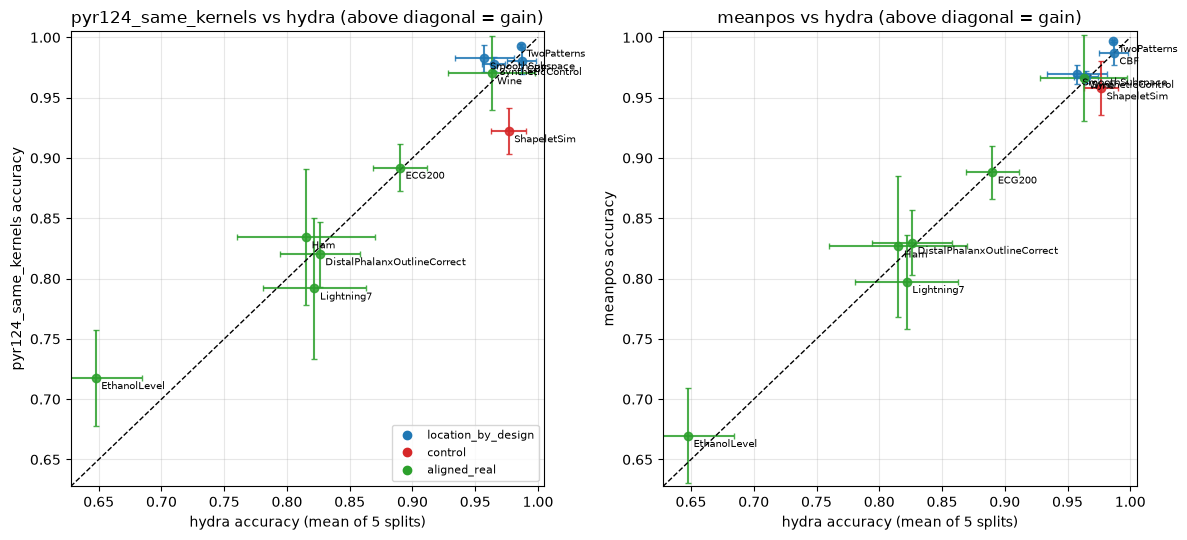

In [21]:
# ---- Figure 1: hydra vs pyr124_same_kernels (and meanpos) per dataset ----
colors = {"location_by_design": "tab:blue", "control": "tab:red", "aligned_real": "tab:green"}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, v in zip(axes, ["pyr124_same_kernels", "meanpos"]):
    for ds in DS_ORDER:
        grp = PILOT_DATASETS[ds][0]
        ax.errorbar(mean_acc.loc[ds, "hydra"], mean_acc.loc[ds, v],
                    xerr=std_acc.loc[ds, "hydra"], yerr=std_acc.loc[ds, v],
                    fmt="o", color=colors[grp], alpha=0.85, capsize=2)
        ax.annotate(ds, (mean_acc.loc[ds, "hydra"], mean_acc.loc[ds, v]), fontsize=7,
                    xytext=(4, -8), textcoords="offset points")
    lo = min(mean_acc["hydra"].min(), mean_acc[v].min()) - 0.02
    ax.plot([lo, 1.0], [lo, 1.0], "k--", lw=1)
    ax.set_xlim(lo, 1.005); ax.set_ylim(lo, 1.005)
    ax.set_xlabel("hydra accuracy (mean of 5 splits)")
    ax.set_ylabel(f"{v} accuracy")
    ax.set_title(f"{v} vs hydra (above diagonal = gain)")
    ax.grid(alpha=0.3)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in colors.items()]
axes[0].legend(handles=handles, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "positional_hydra_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

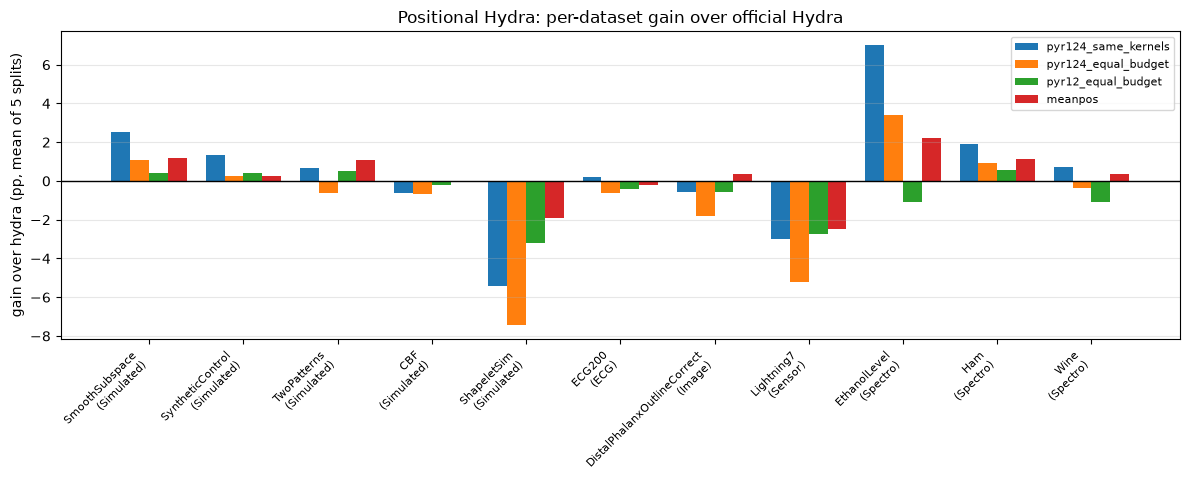

In [22]:
# ---- Figure 2: per-dataset gain of every variant over hydra (pp) ----
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(DS_ORDER))
w = 0.8 / len(OTHERS)
for i, v in enumerate(OTHERS):
    ax.bar(x + (i - (len(OTHERS) - 1) / 2) * w, gain.loc[DS_ORDER, v], width=w, label=v)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x, [f"{d}\n({PILOT_DATASETS[d][1]})" for d in DS_ORDER], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("gain over hydra (pp, mean of 5 splits)")
ax.set_title("Positional Hydra: per-dataset gain over official Hydra")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "positional_hydra_gains.png", dpi=150, bbox_inches="tight")
plt.show()

Mean absolute cost per variant (over datasets and splits):


,n_features,train_transform_s,test_transform_s,fit_s
variant,,,,
hydra,4747.636,1.115,1.592,0.047
pyr124_same_kernels,33233.455,1.431,2.033,0.169
pyr124_equal_budget,5192.727,0.380,0.568,0.047
pyr12_equal_budget,4896.000,0.585,0.847,0.044
meanpos,7121.455,1.237,1.751,0.054


Median cost relative to hydra (x):


,n_features_x,train_transform_s_x,test_transform_s_x,fit_s_x
variant,,,,
hydra,1.00,1.00,1.00,1.00
pyr124_same_kernels,7.00,1.28,1.25,3.56
pyr124_equal_budget,1.09,0.51,0.47,0.97
pyr12_equal_budget,1.03,0.64,0.60,0.98
meanpos,1.50,1.11,1.11,1.20


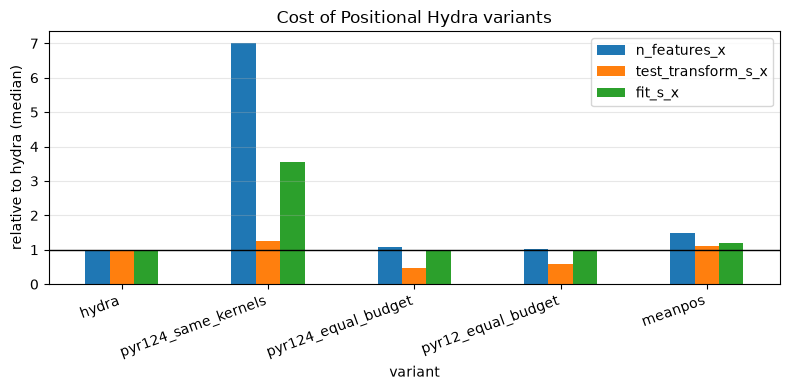

In [23]:
# ---- Table 4 + Figure 3: cost (features and times per variant) ----
cost = res.groupby("variant")[["n_features", "train_transform_s", "test_transform_s", "fit_s"]].mean().reindex(VAR_ORDER)
rel = res.copy()
for col in ["n_features", "train_transform_s", "test_transform_s", "fit_s"]:
    base = rel[rel["variant"] == "hydra"].set_index(["dataset", "resample"])[col]
    rel[col + "_x"] = rel[col].to_numpy() / base.loc[list(zip(rel["dataset"], rel["resample"]))].to_numpy()
cost_rel = rel.groupby("variant")[[c + "_x" for c in ["n_features", "train_transform_s", "test_transform_s", "fit_s"]]] \
              .median().reindex(VAR_ORDER)
print("Mean absolute cost per variant (over datasets and splits):")
display(cost.round(3))
print("Median cost relative to hydra (x):")
display(cost_rel.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
cost_rel[["n_features_x", "test_transform_s_x", "fit_s_x"]].plot.bar(ax=ax)
ax.axhline(1, color="black", lw=1)
ax.set_ylabel("relative to hydra (median)")
ax.set_title("Cost of Positional Hydra variants")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "positional_hydra_cost.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Go / no-go

The next cell computes each criterion from the saved results. **The verdict markdown below it must be written from those printed numbers after the notebook has been run.** It is deliberately left as a template.

In [24]:
loc_ds = [d for d in DS_ORDER if PILOT_DATASETS[d][0] == "location_by_design"]
ctrl_ds = [d for d in DS_ORDER if PILOT_DATASETS[d][0] == "control"]
real_ds = [d for d in DS_ORDER if PILOT_DATASETS[d][0] == "aligned_real"]

print("Q1  gain on the location-by-design datasets (target >= +1 pp) and ShapeletSim (must be >= -0.5 pp):")
for v in ["pyr124_same_kernels", "meanpos"]:
    g_loc = gain.loc[loc_ds, v].mean()
    g_ctrl = gain.loc[ctrl_ds, v].mean() if ctrl_ds else np.nan
    ok = g_loc >= 1.0 and g_ctrl >= -0.5
    print(f"    {v:22s} location-by-design {g_loc:+.2f} pp | ShapeletSim {g_ctrl:+.2f} pp -> {'YES' if ok else 'NO'}")

print("\nQ2  gain on aligned real datasets (per type, pp):")
display(g_df.loc[real_ds].groupby("type")[OTHERS].mean().round(2))
print("    per dataset:")
display(gain.loc[real_ds].round(2))

print("Q3  equal feature budget (the hard test):")
for v in ["pyr124_equal_budget", "pyr12_equal_budget"]:
    d = gain[v]
    print(f"    {v:22s} mean {d.mean():+.2f} pp | W/D/L {int((d > 1e-9).sum())}/{int((d.abs() <= 1e-9).sum())}/"
          f"{int((d < -1e-9).sum())} | location-by-design {d.loc[loc_ds].mean():+.2f} pp")

print("\nQ4  cost (median x hydra):")
display(cost_rel.round(2))

Q1  gain on the location-by-design datasets (target >= +1 pp) and ShapeletSim (must be >= -0.5 pp):
    pyr124_same_kernels    location-by-design +0.98 pp | ShapeletSim -5.44 pp -> NO
    meanpos                location-by-design +0.63 pp | ShapeletSim -1.89 pp -> NO

Q2  gain on aligned real datasets (per type, pp):


variant,pyr124_same_kernels,pyr124_equal_budget,pyr12_equal_budget,meanpos
type,,,,
ECG,0.20,-0.60,-0.40,-0.20
Image,-0.58,-1.81,-0.58,0.36
Sensor,-3.01,-5.21,-2.74,-2.47
Spectro,3.22,1.33,-0.54,1.24


    per dataset:


variant,pyr124_same_kernels,pyr124_equal_budget,pyr12_equal_budget,meanpos
dataset,,,,
ECG200,0.20,-0.60,-0.40,-0.20
DistalPhalanxOutlineCorrect,-0.58,-1.81,-0.58,0.36
Lightning7,-3.01,-5.21,-2.74,-2.47
EthanolLevel,7.00,3.40,-1.08,2.20
Ham,1.90,0.95,0.57,1.14
Wine,0.74,-0.37,-1.11,0.37


Q3  equal feature budget (the hard test):
    pyr124_equal_budget    mean -1.00 pp | W/D/L 4/0/7 | location-by-design +0.01 pp
    pyr12_equal_budget     mean -0.68 pp | W/D/L 4/0/7 | location-by-design +0.27 pp

Q4  cost (median x hydra):


,n_features_x,train_transform_s_x,test_transform_s_x,fit_s_x
variant,,,,
hydra,1.00,1.00,1.00,1.00
pyr124_same_kernels,7.00,1.28,1.25,3.56
pyr124_equal_budget,1.09,0.51,0.47,0.97
pyr12_equal_budget,1.03,0.64,0.60,0.98
meanpos,1.50,1.11,1.11,1.20


### Verdict (fill in from the numbers above after running)

- **Q1: ≥ +1 pp on the location-by-design datasets without hurting ShapeletSim by more than 0.5 pp?** _…_
- **Q2: any gain on the aligned real datasets (ECG, Image, Spectro)?** _…_
- **Q3: does the gain survive at equal feature budget?** _…_
- **Q4: is the extra cost acceptable?** _…_
- **Datasets that behave differently, with a likely reason:** _…_
- **Recommendation (scale to 40 / 112 datasets with 5 resamples plus the MultiRocket check, or stop):** _…_

*Caveats:*
- Pilot only: 11 datasets × 5 splits, so there are no significance claims.
- Resamples are stratified, with the same per-class counts as the default split, but there are only 4 of them (the paper used 30).
- Single machine, with the default thread count. Timings are relative.